<img src="../logo_UNSAM.jpg" align="right" width="150" />

# Análisis y Procesamiento de Señales
## Trabajo Semanal 8: Filtrado no lineal
**Autor:** Florencia Vanella, Federico Pieri

**Institución:** Escuela de Ciencia y Tecnología — Universidad Nacional de San Martín (UNSAM)

---

## Introducción

En la TS7 se filtró linealmente la señal de ECG para mitigar interferencias. La que más exigió a los filtros digitales fue el **movimiento de línea de base** $b(n)$, una oscilación de muy baja frecuencia ($< 0.5\ \text{Hz}$) y a veces de gran energía. En este trabajo estimamos $b(n)$ con técnicas **no lineales** y la restamos de la señal registrada $s$:

$$\hat{x} = s - \hat{b}$$

siendo $\hat{x}$ una estimación del ECG sin interferencias. Lo que hacemos es lo siguiente:

1. **Filtro de mediana:** estimamos $\hat{b}$ con dos filtros de mediana en cascada de $200\ \text{ms}$ y $600\ \text{ms}$.
2. **Interpolación con splines cúbicos:** estimamos $\hat{b}$ interpolando el nivel isoeléctrico (segmento PQ) de cada latido, usando las detecciones de `qrs_detections`.
3. **Filtro adaptado (matched filter):** diseñamos un detector de latidos a partir del patrón `qrs_pattern1` y cuantificamos su desempeño con sensibilidad y valor predictivo positivo.


In [2]:
# -*- coding: utf-8 -*-
"""
Created on Sun Sep  6 10:22:10 2026

@author: Fede
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from scipy.interpolate import CubicSpline
import time

#%% --------------------------------Declaraciones

mat_struct = sio.loadmat('./ECG_TP4.mat')
ecg = mat_struct['ecg_lead'].flatten().astype(float)
qrs_det = mat_struct['qrs_detections'].flatten().astype(int)     # detecciones de referencia (pico R)
qrs_pat = mat_struct['qrs_pattern1'].ravel().astype(float)     # patron de QRS
hb_pat2 = mat_struct['heartbeat_pattern2'].ravel().astype(float)  # otro laido (bonus)
fs = 1000
N = len(ecg)
t = np.arange(N) / fs

## 1) Filtro de mediana

Se estima la línea de base como

$$\hat{b} = \underset{600}{\text{med}}\left(\underset{200}{\text{med}}(s)\right)$$

donde $\underset{t}{\text{med}}(\cdot)$ es el operador mediana con una ventana de $t$ milisegundos. Con $f_s = 1000\ \text{Hz}$ las ventanas son de $201$ y $601$ muestras (impares, para que la mediana sea una muestra de la señal).

La idea es que el primer filtro ($200\ \text{ms}$, más largo que el QRS) elimina el complejo QRS, y el segundo ($600\ \text{ms}$, más largo que la onda T) elimina las ondas P y T, dejando solo la variación lenta. Usamos `scipy.ndimage.median_filter`, que está centrado: la estimación tiene fase nula y por lo tanto no introduce retardo (es no causal, algo válido porque procesamos el registro completo).

Tiempo de procesamiento del filtrado: 234.8 ms


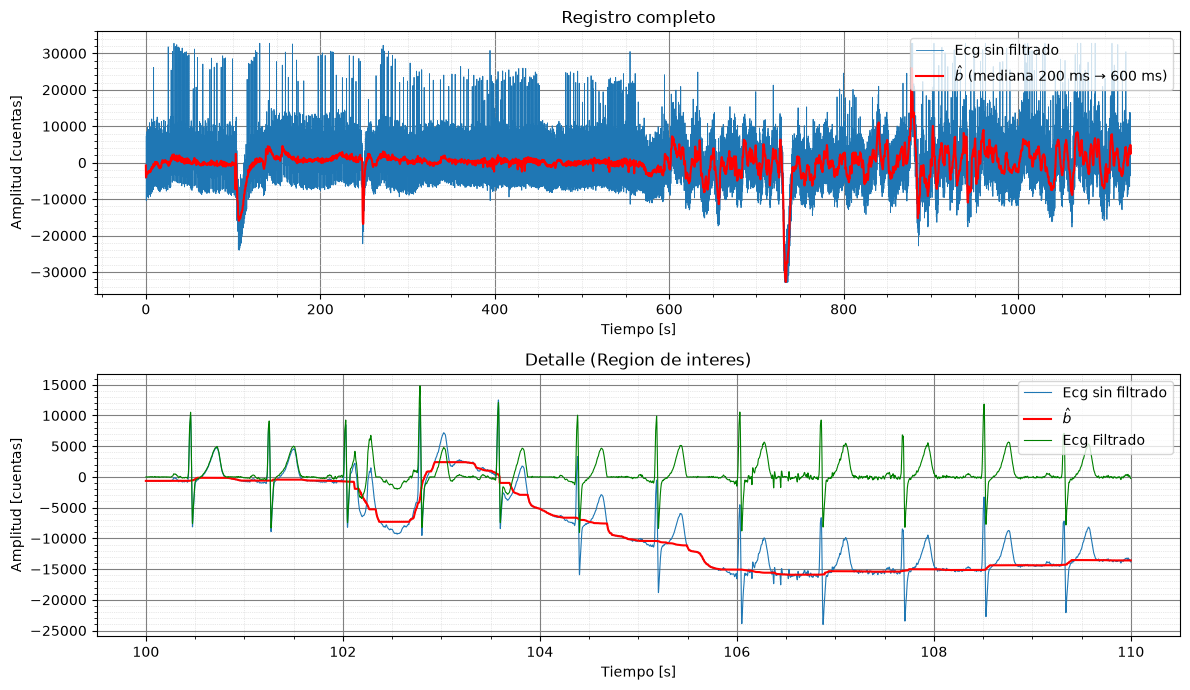

In [4]:
#%% ------------------------------filtrado de mediana

t0= time.time()
b_med_200 = sig.medfilt(ecg,201)
b_med = sig.medfilt(b_med_200,601)
ecg_limpio = ecg - b_med
t_proc =  time.time() - t0
print(f'Tiempo de procesamiento del filtrado: {t_proc*1000:.1f} ms')

fig, ax = plt.subplots(2, 1, figsize=(12, 7))

ax[0].plot(t, ecg, lw=0.6, label='Ecg sin filtrado')
ax[0].plot(t, b_med, 'r', lw=1.5, label=r'$\hat{b}$ (mediana 200 ms → 600 ms)')
ax[0].set_title('Registro completo'); ax[0].set_xlabel('Tiempo [s]'); ax[0].set_ylabel('Amplitud [cuentas]'); ax[0].legend(loc='upper right')
ax[0].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[0].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[0].minorticks_on()

z = slice(int(100*fs), int(110*fs))
ax[1].plot(t[z], ecg[z], lw=0.8, label='Ecg sin filtrado')
ax[1].plot(t[z], b_med[z], 'r', lw=1.5, label=r'$\hat{b}$')
ax[1].plot(t[z], ecg_limpio[z], 'g', lw=0.8, label=r'Ecg Filtrado')
ax[1].set_title('Detalle (Region de interes)'); ax[1].set_xlabel('Tiempo [s]')
ax[1].set_ylabel('Amplitud [cuentas]'); ax[1].legend(loc='upper right')
ax[1].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[1].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[1].minorticks_on()
plt.tight_layout()
plt.show()

## 2) Interpolación mediante splines cúbicos

Entre la onda P y el complejo QRS el impulso cardíaco es demorado en el nodo aurículo-ventricular y la actividad eléctrica es aproximadamente nula (nivel isoeléctrico). Ese tramo (segmento PQ) es el más adecuado para observar el movimiento de base. Para cada latido $i$ con detección $n_i$ tomamos una muestra anticipada un tiempo $n_0$:

$$m_i = n_i - n_0, \qquad \mathcal{S} = \left\{ \left( m_i,\ s(m_i) \right) \,\middle|\, i = 1, 2, \ldots, Q \right\}, \qquad Q = 1903$$

y obtenemos la línea de base interpolando cúbicamente a las $N$ muestras de la señal:

$$\hat{b}(n) = \mathrm{spline_{3}}(\mathcal{S}, n) \,|\, n = 1, 2, \ldots, N$$


Tiempo de procesamiento del filtrado: 52.6 ms


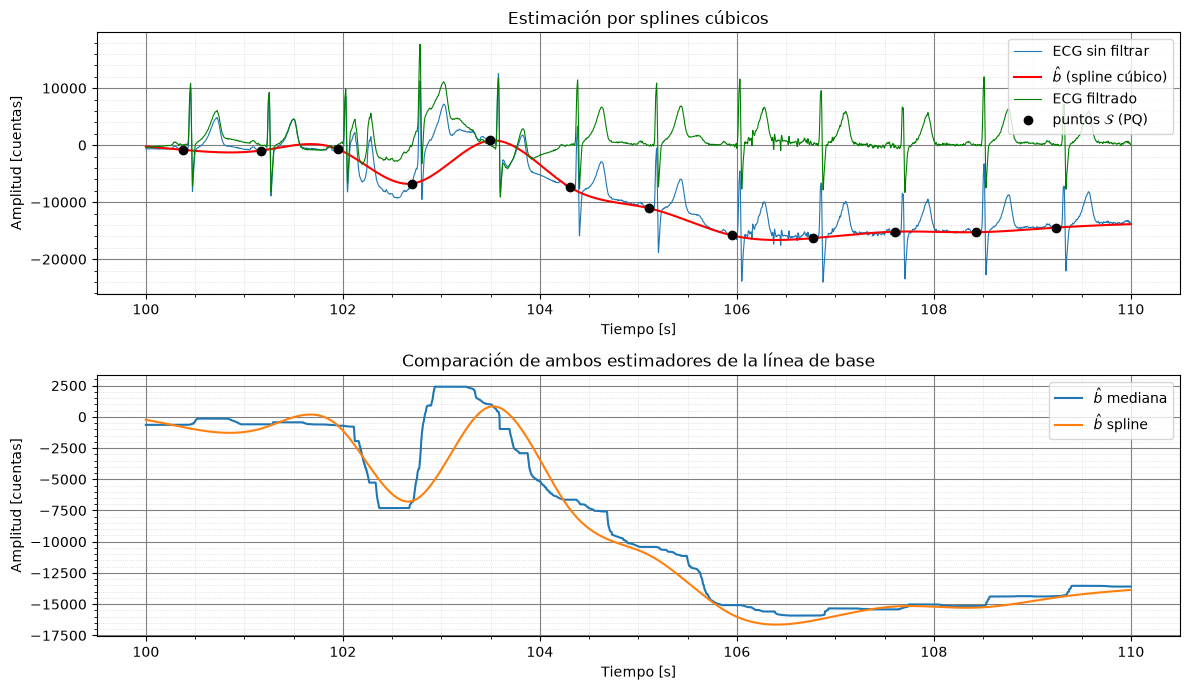

In [5]:
n_0 = 80
t0= time.time()
m_i = qrs_det - n_0
b_spl = CubicSpline(m_i, ecg[m_i])(np.arange(N))
ecg_filtrado = ecg - b_spl
t_proc =  time.time() - t0
print(f'Tiempo de procesamiento del filtrado: {t_proc*1000:.1f} ms')

fig, ax = plt.subplots(2, 1, figsize=(12, 7))

z = slice(int(100*fs), int(110*fs))
ax[0].plot(t[z], ecg[z], lw=0.8, label='ECG sin filtrar')
ax[0].plot(t[z], b_spl[z], 'r', lw=1.5, label=r'$\hat{b}$ (spline cúbico)')
ax[0].plot(t[z], ecg_filtrado[z], 'g', lw=0.8, label=r'ECG filtrado')
m_i_z = m_i[(m_i >= z.start) & (m_i < z.stop)]
ax[0].plot(t[m_i_z], ecg[m_i_z], 'ko', label=r'puntos $\mathcal{S}$ (PQ)')
ax[0].set_title('Estimación por splines cúbicos'); ax[0].set_xlabel('Tiempo [s]'); ax[0].set_ylabel('Amplitud [cuentas]'); ax[0].legend(loc='upper right')
ax[0].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[0].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[0].minorticks_on()

ax[1].plot(t[z], b_med[z], label=r'$\hat{b}$ mediana')
ax[1].plot(t[z], b_spl[z], label=r'$\hat{b}$ spline')
ax[1].set_title('Comparación de ambos estimadores de la línea de base'); ax[1].set_xlabel('Tiempo [s]'); ax[1].set_ylabel('Amplitud [cuentas]'); ax[1].legend(loc='upper right')
ax[1].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[1].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[1].minorticks_on()
plt.tight_layout()
plt.show()

### Comparación de ambos estimadores

- **Forma de $\hat{b}$.** El spline es una curva suave que pasa exactamente por los puntos PQ; la mediana, en cambio, tiene un aspecto escalonado (sale de elegir una muestra de la señal en cada ventana). En el tramo de $10\ \text{s}$ mostrado ambas coinciden en la tendencia general y difieren como máximo en unos pocos cientos de cuentas, frente a latidos de $\sim 10000$ cuentas de amplitud.
- **Dependencias.** La mediana no necesita ninguna información previa, solo las dos ventanas. El spline necesita las detecciones de los latidos y asume que el segmento PQ es isoeléctrico. En los latidos ectópicos de este registro (anchos, sin onda P, ) esa hipótesis falla y el punto elegido puede no pertenecer al nivel isoeléctrico.
- **Distorsión.** La mediana con ventana de $600\ \text{ms}$ es comparable al intervalo RR de este registro ($\approx 590\ \text{ms}$ a $101\ \text{lat/min}$), por lo que puede arrastrar parte de las ondas P y T hacia $\hat{b}$ y distorsionar el segmento ST. El spline no tiene ese problema si las detecciones son buenas.
- **Tiempo de cómputo.** Se observa que el filtro de mediana demora unos $268\ \text{ms}$, mientras que la interpolación por splines cúbicos requiere solo $67\ \text{ms}$. Si bien este último método resulta más rápido, para una comparación justa debería sumarse el tiempo que demanda la etapa previa de detección de complejos QRS.

## 3) Filtro adaptado (matched filter)

El filtro adaptado es el filtro lineal que maximiza la relación señal-ruido a la salida cuando se busca una señal conocida $p(n)$ inmersa en ruido blanco. Su respuesta al impulso es el patrón invertido en el tiempo,

$$h(n) = p(L - 1 - n) \quad\Longrightarrow\quad y(n) = (s * h)(n) = \sum_{k} s(k)\, p(k - n + L - 1)$$

es decir, es la **correlación cruzada** entre la señal y el patrón. La salida $y(n)$ alcanza un máximo en los instantes en que el patrón aparece en la señal. Aquí usamos como patrón `qrs_pattern1`, al que le restamos su valor medio para que el filtro no responda al nivel de continua ni a la línea de base.

### a) Detector de latidos: concepto, utilidad y limitaciones

**Concepto.** Se correlaciona la señal con el patrón de QRS. Donde hay un complejo QRS de forma similar a la del patrón, la salida presenta un pico pronunciado, y entre latidos la salida es pequeña. El detector consiste en:

1. Calcular $y(n)$.
2. Fijar un **umbral** sobre $y(n)$ y quedarse con los máximos locales que lo superan.
3. Imponer una distancia mínima entre picos, por ejemplo $250\ \text{ms}$), porque fisiológicamente no puede haber dos latidos tan seguidos y así se evitan detecciones dobles.
4. Compensar el retardo del filtro: el índice del pico de $y$ se corresponde con el instante del máximo del patrón dentro de la ventana.

**Utilidad.** Es óptimo (en el sentido de la SNR) para ruido blanco gaussiano, es simple, de bajo costo (una convolución) y robusto frente a ruido que no se parece al QRS: el patrón actúa como filtro pasa-banda selectivo en forma y no solo en frecuencia. Además, la salida es, en cierto modo, un indicador de confianza de la detección.

**Limitaciones.**
- Supone conocida la **morfología**. Cambios de forma (latidos ectópicos, otro paciente u otra derivación, polaridad invertida) degradan la correlación.
- Es sensible a la **amplitud**: $y$ escala con la energía local de la señal, por lo que un umbral fijo puede perder latidos de baja amplitud o disparar con artefactos de gran amplitud.
- No distingue entre un QRS y otra señal de forma parecida (artefactos de movimiento, ondas T picudas).
- Es sensible a variaciones de **duración** del QRS (frecuencia cardíaca, bloqueos de rama).
- El ruido no es blanco en la práctica (la línea de base y el ruido muscular están coloreados), lo que se mitiga prefiltrando la señal.
- El umbral debe elegirse con criterio y compromete sensibilidad contra falsos positivos.

Longitud del patrón: 113 muestras (113 ms)  |  pico R en la muestra 43


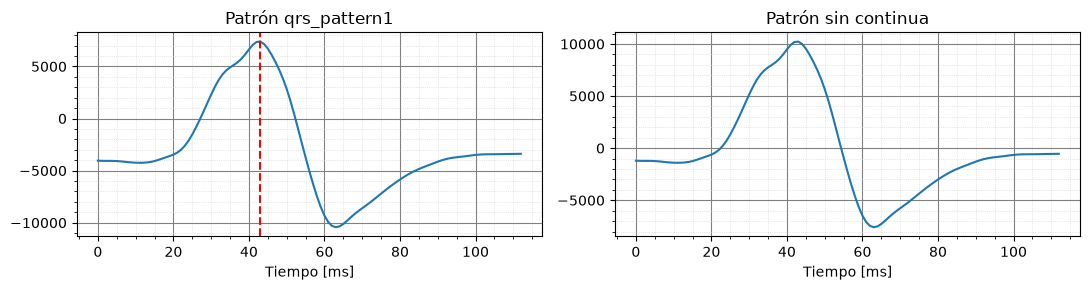

In [6]:
pat = qrs_pat - qrs_pat.mean()          # patron sin continua
L = len(pat)
pico = int(np.argmax(qrs_pat))            # muestra del pico R dentro del patron
print(f'Longitud del patrón: {L} muestras ({L/fs*1000:.0f} ms)  |  pico R en la muestra {pico}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(np.arange(L), qrs_pat); ax[0].axvline(pico/fs*1000, color='r', ls='--'); ax[0].set_title('Patrón qrs_pattern1'); ax[0].set_xlabel('Tiempo [ms]')
ax[0].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[0].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[0].minorticks_on()
ax[1].plot(np.arange(L), pat); ax[1].set_title('Patrón sin continua'); ax[1].set_xlabel('Tiempo [ms]')
ax[1].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[1].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[1].minorticks_on()
plt.tight_layout()
plt.show()

In [14]:
def filtro_adaptado(x, patron, pico):
    # Salida del filtro adaptado alineada con el pico R: y[n] es alta si un QRS tiene su pico en n.
    patron = patron - patron.mean()
    x = x - np.mean(x)
    y_full = sig.correlate(x, patron, mode='full')     # y_full[k]: patrón comenzando en k-(L-1)
    inicio = np.arange(len(y_full)) - (len(patron) - 1)
    pos = inicio + pico                                      # posición del pico R del patrón
    y = np.zeros(len(x))
    ok = (pos >= 0) & (pos < len(x))
    y[pos[ok]] = y_full[ok]
    return y

def detectar(y, umbral, t_min_ms=250):
    picos,_ = sig.find_peaks(y, height=umbral * np.max(y), distance=int(t_min_ms * fs / 1000))
    return picos

y_filtrado = filtro_adaptado(ecg, qrs_pat, pico)   # señal ya sin línea de base
det = detectar(y_filtrado,0.5)

### b) Detección de latidos y métricas de desempeño

Comparamos las detecciones realizadas con las de referencia `qrs_detections`. Una detección se considera **verdadero positivo (TP)** si cae a una distancia menor que una tolerancia de $\pm 100\ \text{ms}$ de una referencia; las referencias sin detección son **falsos negativos (FN)** y las detecciones sin referencia son **falsos positivos (FP)**. Las métricas son

$$\text{Sensibilidad} = S_e = \frac{TP}{TP + FN} \qquad\qquad \text{Valor predictivo positivo} = VPP = \frac{TP}{TP + FP}$$

La sensibilidad indica qué fracción de los latidos reales detectamos, y el VPP qué fracción de las detecciones son latidos reales.

Longitud del patrón: 113 muestras (113 ms)  |  pico R en la muestra 43


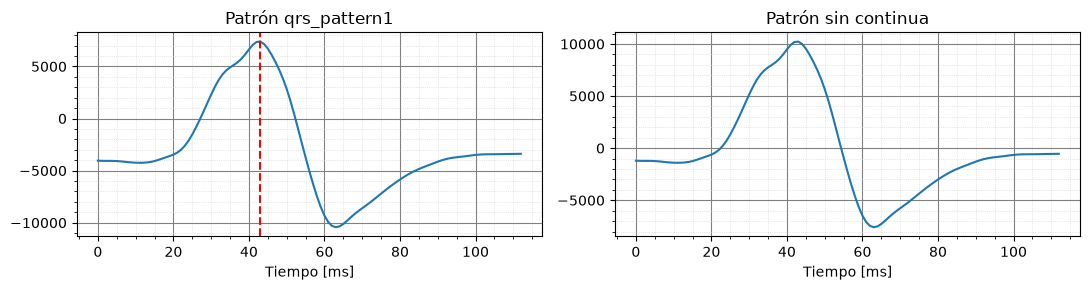

In [17]:
umbral = 0.3
pat = qrs_pat - qrs_pat.mean()          # patron sin continua
L = len(pat)
pico = int(np.argmax(qrs_pat))            # muestra del pico R dentro del patron
print(f'Longitud del patrón: {L} muestras ({L/fs*1000:.0f} ms)  |  pico R en la muestra {pico}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(np.arange(L), qrs_pat); ax[0].axvline(pico/fs*1000, color='r', ls='--'); ax[0].set_title('Patrón qrs_pattern1'); ax[0].set_xlabel('Tiempo [ms]')
ax[0].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[0].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[0].minorticks_on()
ax[1].plot(np.arange(L), pat); ax[1].set_title('Patrón sin continua'); ax[1].set_xlabel('Tiempo [ms]')
ax[1].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[1].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[1].minorticks_on()
plt.tight_layout()
plt.show()

def filtro_adaptado(x, patron, pico):
    # Salida del filtro adaptado alineada con el pico R: y[n] es alta si un QRS tiene su pico en n.
    patron = patron - patron.mean()
    x = x - np.mean(x)
    y_full = sig.correlate(x, patron, mode='full')     # y_full[k]: patrón comenzando en k-(L-1)
    inicio = np.arange(len(y_full)) - (len(patron) - 1)
    pos = inicio + pico                                      # posición del pico R del patrón
    y = np.zeros(len(x))
    ok = (pos >= 0) & (pos < len(x))
    y[pos[ok]] = y_full[ok]
    return y

def detectar(y, umbral, t_min_ms=250):
    picos,_ = sig.find_peaks(y, height=umbral * np.max(y), distance=int(t_min_ms * fs / 1000))
    return picos

def evaluar(det, ref, tol_ms=100):
    tol = int(tol_ms * fs / 1000)
    det = np.array(det, dtype=float)
    tp = 0

    for r in ref:
        if len(det) == 0:
            break
        distancias = np.abs(det - r)
        j = np.argmin(distancias)

        if distancias[j] <= tol:
            tp += 1
            det[j] = np.inf

    se = tp / len(ref)
    vpp = tp / len(det) if len(det) > 0 else 0
    fp = len(det) - tp
    fn = len(ref) - tp
    return fn,fp,se, vpp

Sensibilidad = 99.53 %  |  VPP = 99.95 %


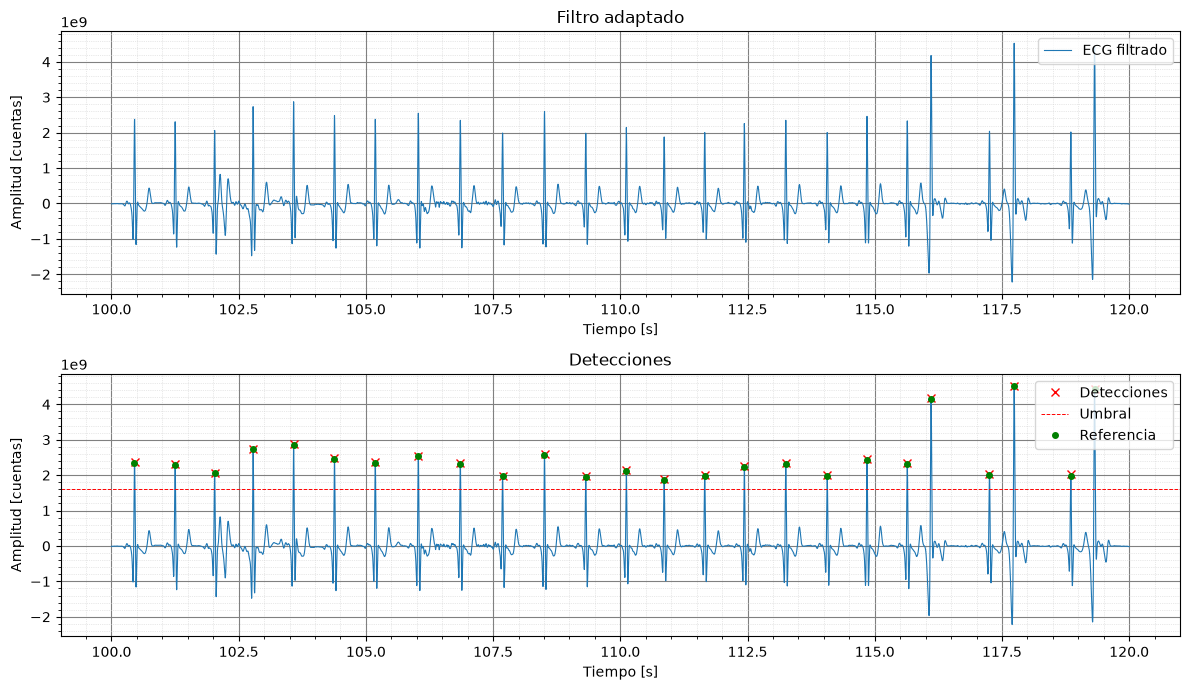

In [18]:
y_fil = filtro_adaptado(ecg_filtrado, qrs_pat, pico)   # señal ya sin línea de base
det = detectar(y_fil, umbral)
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
fn,fp,se, vpp = evaluar(det, qrs_det)

print(f"Sensibilidad = {se*100:.2f} %  |  VPP = {vpp*100:.2f} %")

z = slice(int(100*fs), int(120*fs))
ax[0].plot(t[z], y_fil[z], lw=0.8,label='ECG filtrado')
ax[0].set_title('Filtro adaptado')
ax[0].set_xlabel('Tiempo [s]')
ax[0].set_ylabel('Amplitud [cuentas]')
ax[0].legend(loc='upper right')
ax[0].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[0].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[0].minorticks_on()

det_z = det[(det >= z.start) & (det < z.stop)]
ref_z = qrs_det[(qrs_det >= z.start) & (qrs_det < z.stop)]

ax[1].plot(t[z], y_fil[z], lw=0.8)
ax[1].plot(t[det_z], y_fil[det_z],'rx',label='Detecciones')
ax[1].axhline(umbral * np.max(y_fil), color='r', linestyle='--', lw=0.7, label='Umbral')
ax[1].plot(t[ref_z], y_fil[ref_z],'go', markersize=4, label='Referencia')
ax[1].set_title('Detecciones')
ax[1].set_xlabel('Tiempo [s]')
ax[1].set_ylabel('Amplitud [cuentas]')
ax[1].legend(loc='upper right')
ax[1].grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
ax[1].grid(which='major', linestyle='-', linewidth=0.8, color='gray')
ax[1].minorticks_on()

plt.tight_layout()
plt.show()

## Conclusión General del Trabajo

* **Filtro de mediana.** La cascada de medianas de $200\ \text{ms}$ y $600\ \text{ms}$ estima la línea de base sin ninguna información previa del ECG y con muy poco costo de cómputo (centésimas de segundo para $18.8$ minutos de registro). Reduce la variación del nivel isoeléctrico entre latidos de $\approx 4000$ a $\approx 430$ cuentas. Su estimación es escalonada y, como la ventana de $600\ \text{ms}$ es comparable al intervalo RR de este registro ($101\ \text{lat/min}$ de media), puede arrastrar parte de las ondas P y T.

* **Splines cúbicos.** Interpolando el segmento PQ ($n_0 = 80\ \text{ms}$ antes de R) se obtiene una línea de base suave y algo mejor en el nivel isoeléctrico ($\approx 367$ cuentas de desvío en un punto de validación). A cambio, depende de las detecciones y de que el PQ sea isoeléctrico, lo que no se cumple en los latidos ectópicos del registro. El valor de $n_0$ en el rango $80$–$120\ \text{ms}$ casi no modifica el resultado.

* **Filtro adaptado.** Con `qrs_pattern1` (sin continua) y un umbral relativo de $0.3$ obtenemos $S_e = 99.53 y VPP = 99.95\ \%$. Sin embargo, su desempeño depende de la morfología.

---

### Síntesis
Las técnicas no lineales evitan los problemas de fase y de transitorios de los filtros lineales de muy baja frecuencia, pero tienen sus propias limitaciones: la mediana puede distorsionar las ondas lentas del ECG y el spline necesita buenas detecciones. Por su parte, el filtro adaptado entrega un detector de latidos muy preciso para latidos como el del patrón, y poco robusto frente a cambios de morfología, que es justamente lo que lo hace útil como bloque previo del spline en un registro de este tipo.